# **Uncoordinated 2 robots patrolling**



Running 1,000,000 steps...


100%|██████████| 1000000/1000000 [01:05<00:00, 15181.91it/s]



Simulation Complete.

FINAL RESULTS
Mean IAI: 50.7599
Mean MaxIdle: 102.8972
Maximum Observed Idleness: 215
Final IAI: 50.4400
Final MaxIdle: 102.0
Unique IAI values (tail): 101
Unique MaxIdle values (tail): 3


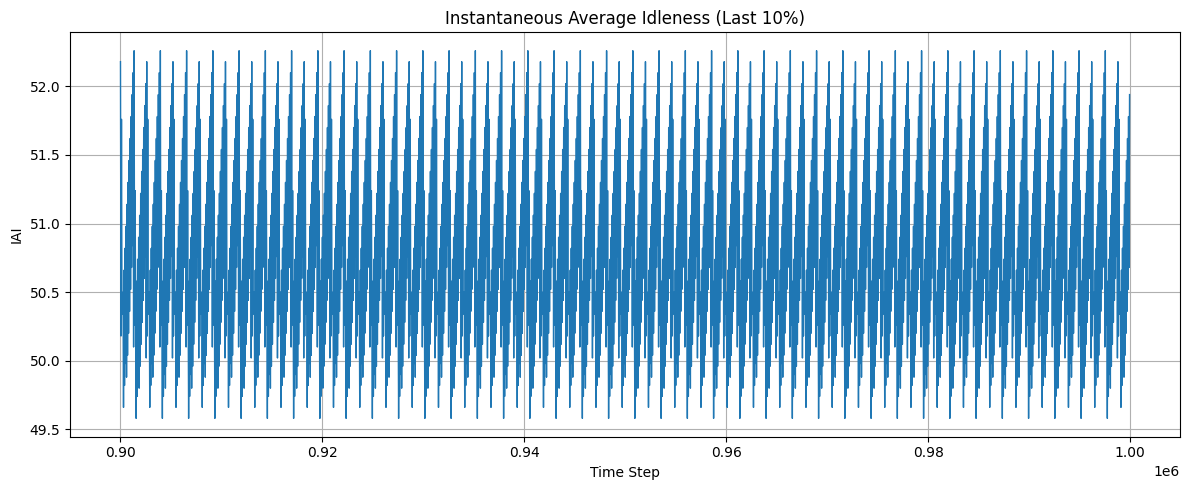

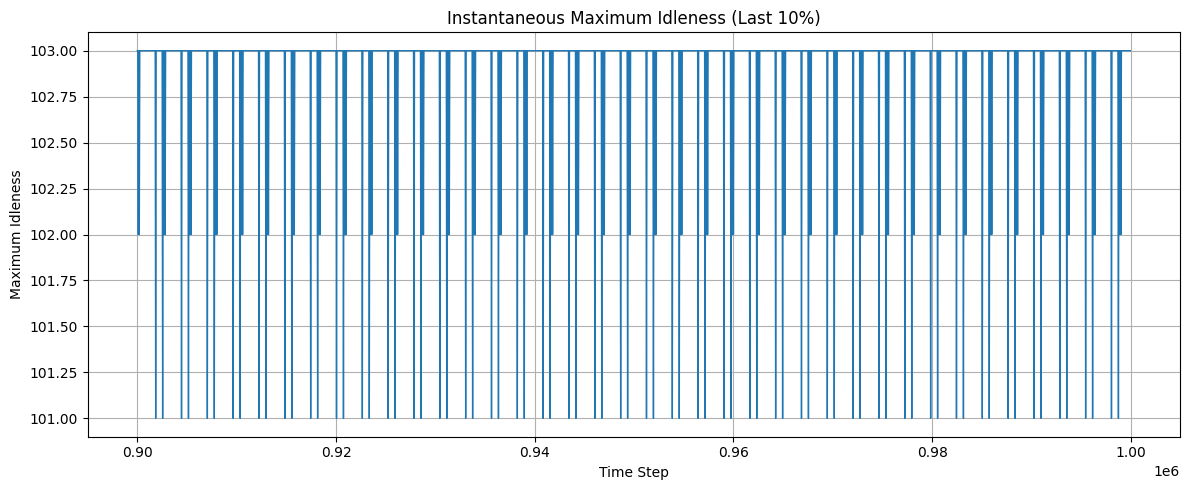


Final Idleness Map:

[[ 28  29  30  31  32  33  70  69  66  65]
 [ 27  26  37  36  35  34  71  68  67  64]
 [ 24  25  38  55  56  57  72  73  74  63]
 [ 23  40  39  54   1   0  59  60  61  62]
 [ 22  41  52  53   2   3 102 101 100  77]
 [ 21  42  51  50   5   4  93  94  99  78]
 [ 20  43  44  49   6  91  92  95  98  79]
 [ 19  18  45  48   7  90  89  96  97  80]
 [ 16  17  46  47   8   9  88  85  84  81]
 [ 15  14  13  12  11  10  87  86  83  82]]


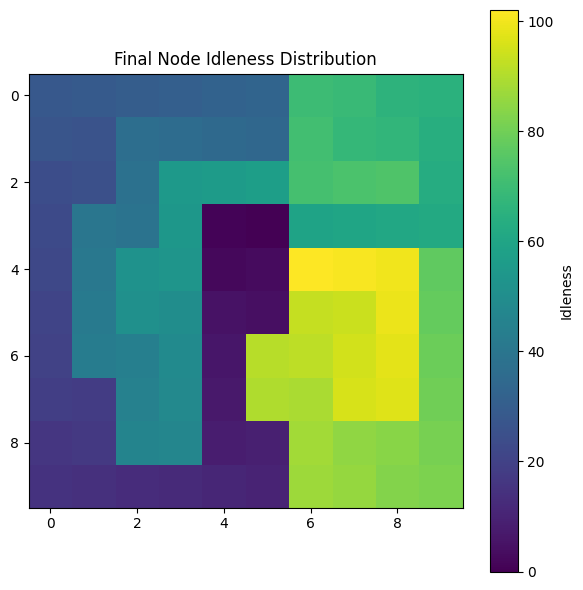

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm


# ==========================================================
# Build 10x10 Grid Graph
# ==========================================================

def build_grid_graph(rows=10, cols=10):
    neighbors = []

    for r in range(rows):
        for c in range(cols):

            nbrs = []

            if r > 0:
                nbrs.append((r - 1) * cols + c)

            if r < rows - 1:
                nbrs.append((r + 1) * cols + c)

            if c > 0:
                nbrs.append(r * cols + c - 1)

            if c < cols - 1:
                nbrs.append(r * cols + c + 1)

            neighbors.append(np.array(nbrs, dtype=np.int32))

    return neighbors


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):
        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PersistentPatrolling:

    def __init__(
        self,
        rows=10,
        cols=10,
        num_steps=1_000_000,
        seed=42
    ):

        self.rows = rows
        self.cols = cols
        self.N = rows * cols
        self.num_steps = num_steps

        self.rng = np.random.default_rng(seed)

        self.neighbors = build_grid_graph(rows, cols)

        # Opposite corners
        self.robot1 = HIFRobot(
            start_node=0,
            neighbors=self.neighbors,
            rng=self.rng
        )

        self.robot2 = HIFRobot(
            start_node=self.N - 1,
            neighbors=self.neighbors,
            rng=self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        # Only store last 10%
        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        # Running statistics
        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        # Increase idleness
        self.idleness += 1

        # Move robots independently
        node1 = self.robot1.move(self.idleness)
        node2 = self.robot2.move(self.idleness)

        # Reset visited nodes
        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        print(
            f"\nRunning {self.num_steps:,} steps..."
        )

        tail_idx = 0

        for t in tqdm(range(self.num_steps)):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            if max_idle > self.global_max_idle:
                self.global_max_idle = max_idle

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

        print("\nSimulation Complete.")

    def print_statistics(self):

        print("\n======================")
        print("FINAL RESULTS")
        print("======================")

        print(
            f"Mean IAI: "
            f"{self.iai_sum/self.num_steps:.4f}"
        )

        print(
            f"Mean MaxIdle: "
            f"{self.max_sum/self.num_steps:.4f}"
        )

        print(
            f"Maximum Observed Idleness: "
            f"{self.global_max_idle}"
        )

        print(
            f"Final IAI: "
            f"{self.iai_tail[-1]:.4f}"
        )

        print(
            f"Final MaxIdle: "
            f"{self.max_tail[-1]}"
        )

        print(
            f"Unique IAI values (tail): "
            f"{len(np.unique(self.iai_tail))}"
        )

        print(
            f"Unique MaxIdle values (tail): "
            f"{len(np.unique(self.max_tail))}"
        )

    def plot_last_10_percent(self):

        x = np.arange(
            self.tail_start,
            self.num_steps
        )

        # Downsample for readability
        stride = max(1, len(x) // 2000)

        plt.figure(figsize=(12,5))

        plt.plot(
            x[::stride],
            self.iai_tail[::stride],
            linewidth=1
        )

        plt.title(
            "Instantaneous Average Idleness (Last 10%)"
        )

        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)
        plt.tight_layout()

        plt.figure(figsize=(12,5))

        plt.plot(
            x[::stride],
            self.max_tail[::stride],
            linewidth=1
        )

        plt.title(
            "Instantaneous Maximum Idleness (Last 10%)"
        )

        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)
        plt.tight_layout()

        plt.show()

    def show_final_idleness_map(self):

        print("\nFinal Idleness Map:\n")

        print(
            self.idleness.reshape(
                self.rows,
                self.cols
            )
        )

        plt.figure(figsize=(6,6))

        plt.imshow(
            self.idleness.reshape(
                self.rows,
                self.cols
            ),
            origin="upper"
        )

        plt.colorbar(label="Idleness")

        plt.title(
            "Final Node Idleness Distribution"
        )

        plt.tight_layout()
        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    # Debug first:
    STEPS = 10_00_000

    # For final experiment:
    # STEPS = 1_000_000

    sim = PersistentPatrolling(
        rows=10,
        cols=10,
        num_steps=STEPS,
        seed=42
    )

    sim.run()

    sim.print_statistics()

    sim.plot_last_10_percent()



    sim.show_final_idleness_map()

# **Coordinated 2 robots Patrolling**

Running: 100%|██████████| 1000000/1000000 [01:16<00:00, 13059.51it/s]



===== RESULTS =====
Mean IAI: 25.611323119986604
Mean MaxIdle: 57.932757
Maximum Observed Idleness: 179
Final IAI: 25.32
Final MaxIdle: 57

Diagnostics
IAI range: 24.8 26.2
MaxIdle range: 55 57


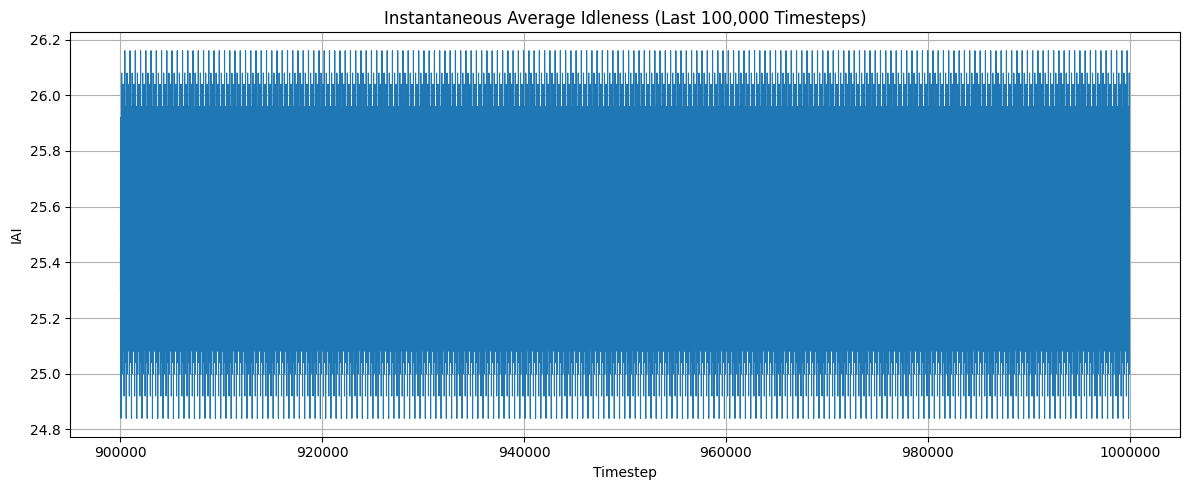

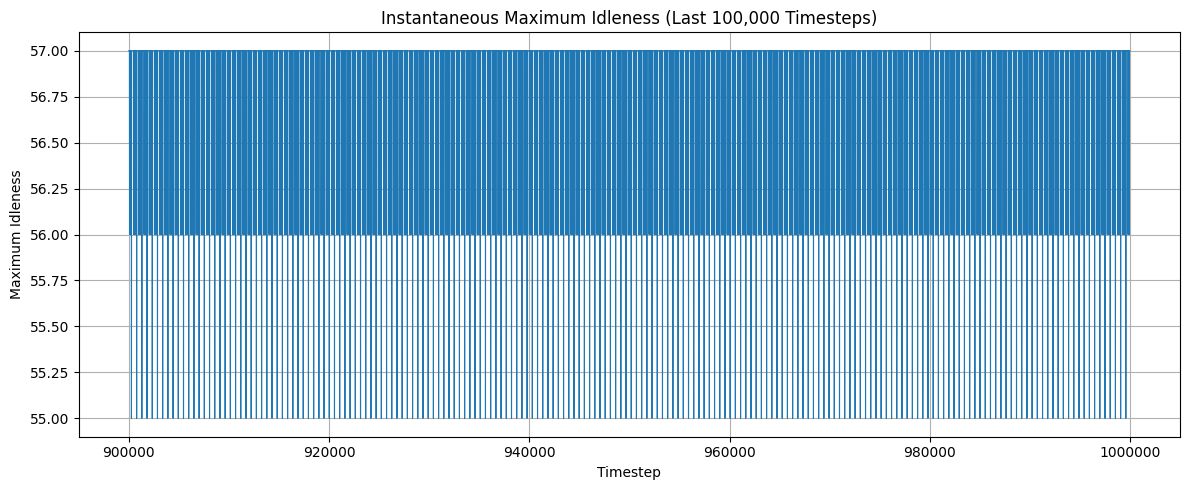

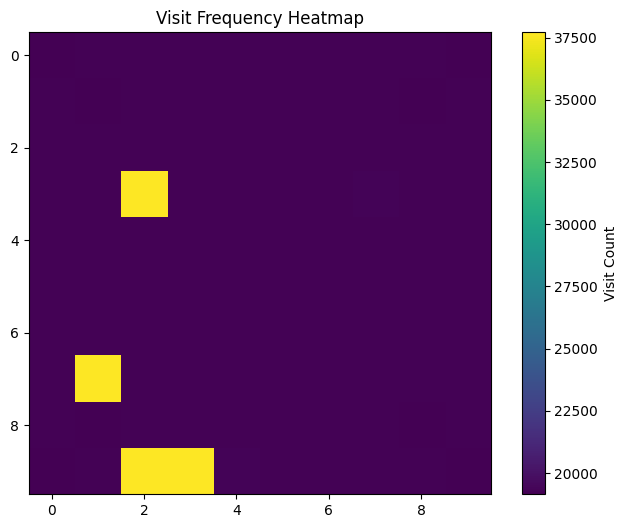

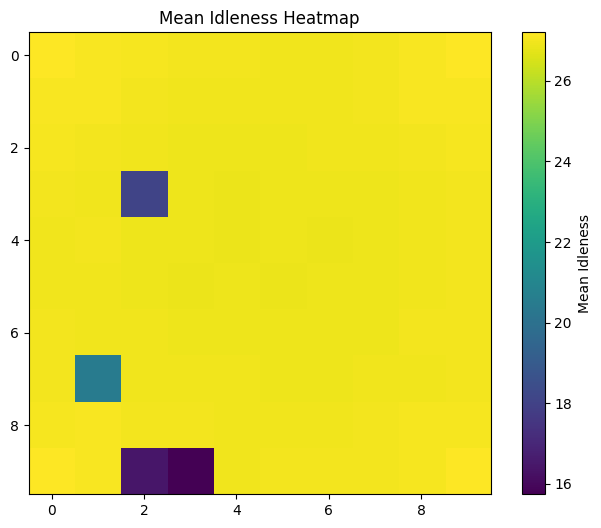

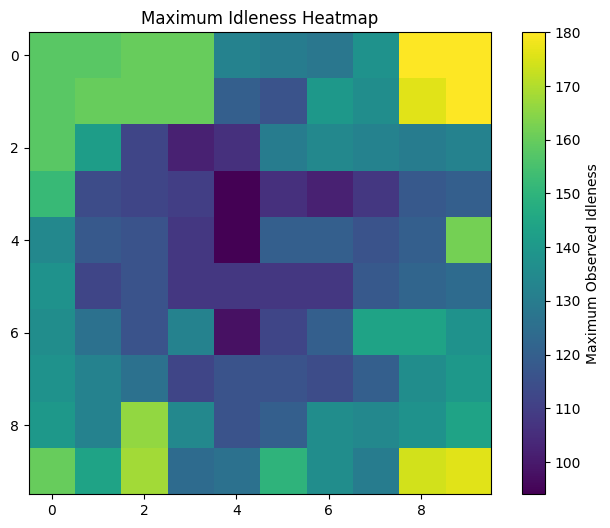

In [ ]:

# Sequential Coordinated HIF Persistent Patrolling
# Robot 1 chooses first; Robot 2 sees Robot 1 destination and avoids it if possible.

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

def build_grid_graph(rows=10, cols=10):
    neighbors = [[] for _ in range(rows * cols)]
    for r in range(rows):
        for c in range(cols):
            n = r * cols + c
            if r > 0: neighbors[n].append((r - 1) * cols + c)
            if r < rows - 1: neighbors[n].append((r + 1) * cols + c)
            if c > 0: neighbors[n].append(r * cols + c - 1)
            if c < cols - 1: neighbors[n].append(r * cols + c + 1)
    return neighbors

class Robot:
    def __init__(self, start, rng):
        self.position = start
        self.rng = rng

    def choose_next(self, neighbors, idleness, forbidden=None):
        nbrs = neighbors[self.position]
        if forbidden is not None:
            filt = [n for n in nbrs if n != forbidden]
            if filt:
                nbrs = filt
        nbrs = np.array(nbrs)
        vals = idleness[nbrs]
        mx = vals.max()
        candidates = nbrs[vals == mx]
        return int(self.rng.choice(candidates))

class Simulation:
    def __init__(self, rows=10, cols=10, timesteps=1_000_000, seed=42):
        self.rows = rows
        self.cols = cols
        self.timesteps = timesteps
        self.n_nodes = rows * cols

        self.rng = np.random.default_rng(seed)
        self.neighbors = build_grid_graph(rows, cols)

        self.idleness = np.zeros(self.n_nodes, dtype=np.int32)

        starts = [0, self.n_nodes - 1]
        self.robots = [Robot(starts[0], self.rng), Robot(starts[1], self.rng)]

        self.visit_count = np.zeros(self.n_nodes, dtype=np.int64)
        self.idle_sum = np.zeros(self.n_nodes, dtype=np.float64)
        self.max_idle_per_node = np.zeros(self.n_nodes, dtype=np.int32)

        for s in starts:
            self.visit_count[s] += 1

        self.sum_iai = 0.0
        self.sum_max = 0.0
        self.global_max = 0

        self.store_start = int(0.9 * timesteps)
        tail_size = timesteps - self.store_start

        self.iai_tail = np.empty(tail_size, dtype=np.float32)
        self.max_tail = np.empty(tail_size, dtype=np.int32)

    def coordinated_move(self):
        r1, r2 = self.robots

        next1 = r1.choose_next(self.neighbors, self.idleness)

        next2 = r2.choose_next(
            self.neighbors,
            self.idleness,
            forbidden=next1
        )

        r1.position = next1
        r2.position = next2

        return [next1, next2]

    def step(self):
        self.idleness += 1

        self.idle_sum += self.idleness
        self.max_idle_per_node = np.maximum(
            self.max_idle_per_node,
            self.idleness
        )

        visited = self.coordinated_move()

        self.idleness[visited] = 0

        for v in visited:
            self.visit_count[v] += 1

    def run(self):
        idx = 0

        for t in tqdm(range(self.timesteps), desc="Running"):
            self.step()

            iai = self.idleness.mean()
            mx = self.idleness.max()

            self.sum_iai += iai
            self.sum_max += mx
            self.global_max = max(self.global_max, int(mx))

            if t >= self.store_start:
                self.iai_tail[idx] = iai
                self.max_tail[idx] = mx
                idx += 1

def plot_time_series(sim):

    # Entire last 10% of simulation
    x = np.arange(
        sim.store_start,
        sim.timesteps
    )

    iai = sim.iai_tail
    mx = sim.max_tail

    # Downsample only for plotting
    stride = 10

    # -------------------------
    # IAI Plot
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        x[::stride],
        iai[::stride],
        linewidth=0.8
    )

    plt.title(
        "Instantaneous Average Idleness (Last 100,000 Timesteps)"
    )

    plt.xlabel("Timestep")
    plt.ylabel("IAI")

    plt.ticklabel_format(
        style='plain',
        axis='x'
    )

    plt.grid(True)

    plt.tight_layout()

    # -------------------------
    # Max Idle Plot
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        x[::stride],
        mx[::stride],
        linewidth=0.8
    )

    plt.title(
        "Instantaneous Maximum Idleness (Last 100,000 Timesteps)"
    )

    plt.xlabel("Timestep")
    plt.ylabel("Maximum Idleness")

    plt.ticklabel_format(
        style='plain',
        axis='x'
    )

    plt.grid(True)

    plt.tight_layout()

    plt.show()

def plot_heatmaps(sim):
    visit = sim.visit_count.reshape(sim.rows, sim.cols)

    mean_idle = (
        sim.idle_sum / sim.timesteps
    ).reshape(sim.rows, sim.cols)

    max_idle = sim.max_idle_per_node.reshape(
        sim.rows,
        sim.cols
    )

    plt.figure(figsize=(8,6))
    plt.imshow(visit)
    plt.colorbar(label="Visit Count")
    plt.title("Visit Frequency Heatmap")

    plt.figure(figsize=(8,6))
    plt.imshow(mean_idle)
    plt.colorbar(label="Mean Idleness")
    plt.title("Mean Idleness Heatmap")

    plt.figure(figsize=(8,6))
    plt.imshow(max_idle)
    plt.colorbar(label="Maximum Observed Idleness")
    plt.title("Maximum Idleness Heatmap")

    plt.show()

def main():
    sim = Simulation(
        rows=10,
        cols=10,
        timesteps=1_000_000,
        seed=42
    )

    sim.run()

    print("\n===== RESULTS =====")
    print("Mean IAI:", sim.sum_iai / sim.timesteps)
    print("Mean MaxIdle:", sim.sum_max / sim.timesteps)
    print("Maximum Observed Idleness:", sim.global_max)
    print("Final IAI:", sim.iai_tail[-1])
    print("Final MaxIdle:", sim.max_tail[-1])

    print("\nDiagnostics")
    print("IAI range:", sim.iai_tail.min(), sim.iai_tail.max())
    print("MaxIdle range:", sim.max_tail.min(), sim.max_tail.max())

    plot_time_series(sim)
    plot_heatmaps(sim)

if __name__ == "__main__":
    main()


# **Uncoordinated and coordinated 2 Robots patrolling (10 percent removed)**

###**1st Case**

Removed 18 edges from 180 total edges


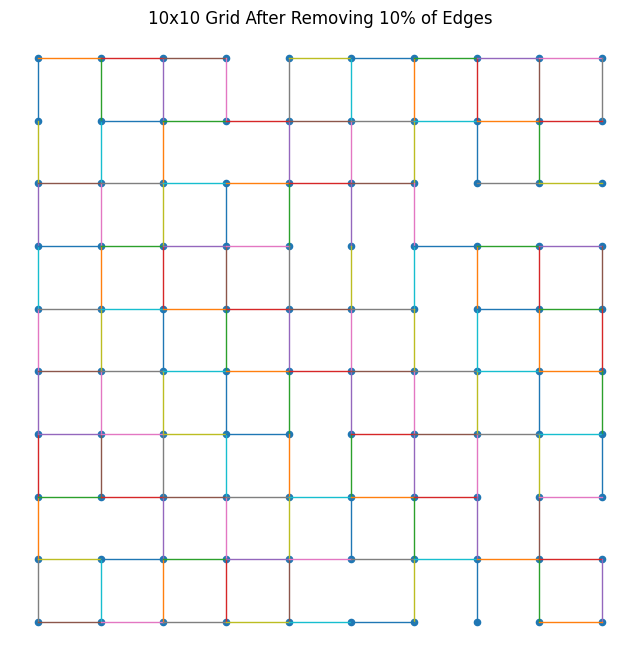

Uncoordinated: 100%|██████████| 1000000/1000000 [01:10<00:00, 14259.84it/s]



UNCOORDINATED
Mean IAI: 53.821947920102055
Mean MaxIdle: 109.706034
Maximum Observed Idleness: 341
Final IAI: 51.84
Final MaxIdle: 109.0


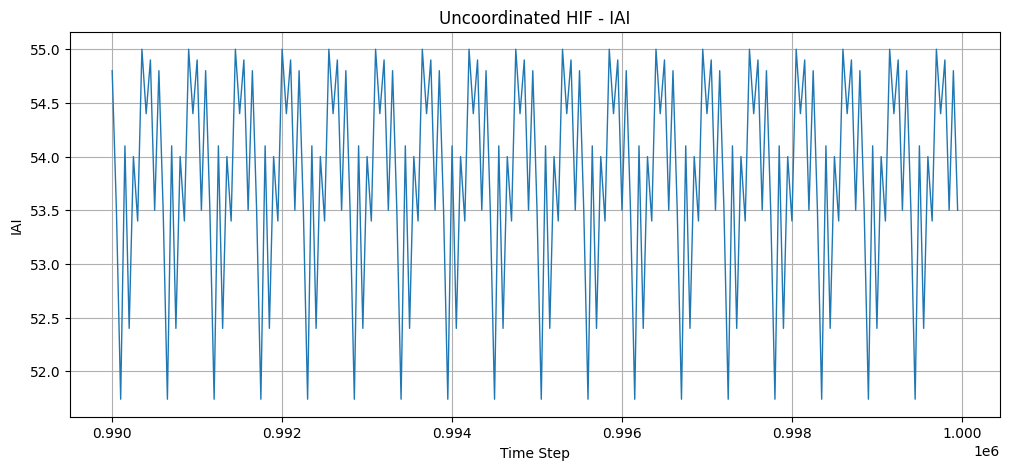

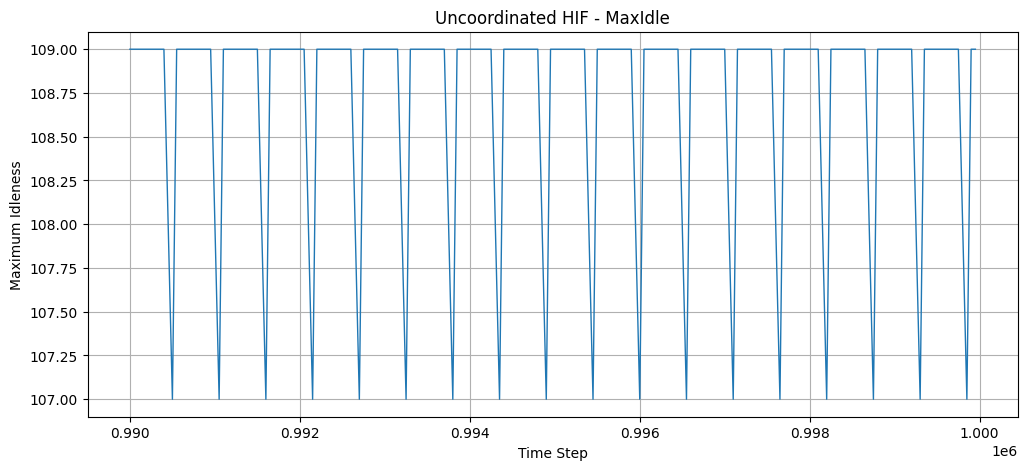

Coordinated: 100%|██████████| 1000000/1000000 [01:19<00:00, 12527.96it/s]



COORDINATED
Mean IAI: 27.988272860099055
Mean MaxIdle: 67.568504
Maximum Observed Idleness: 211
Final IAI: 26.8
Final MaxIdle: 63.0


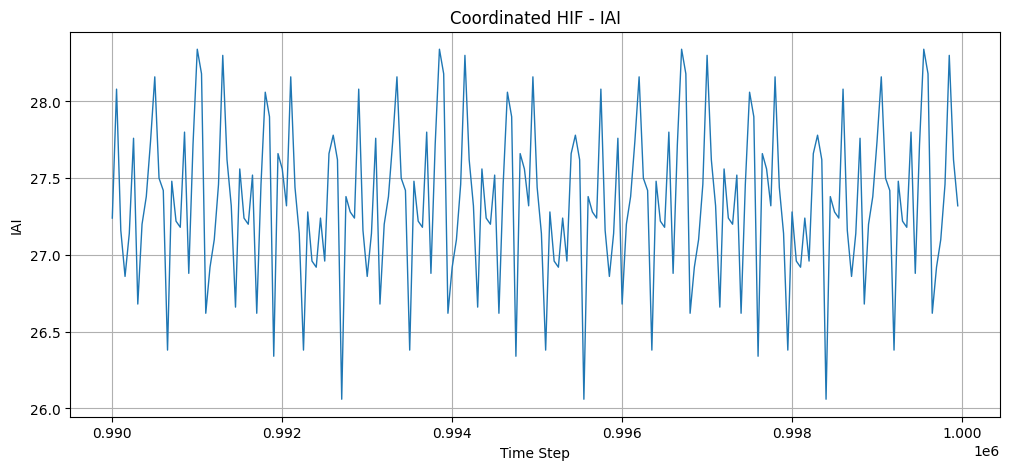

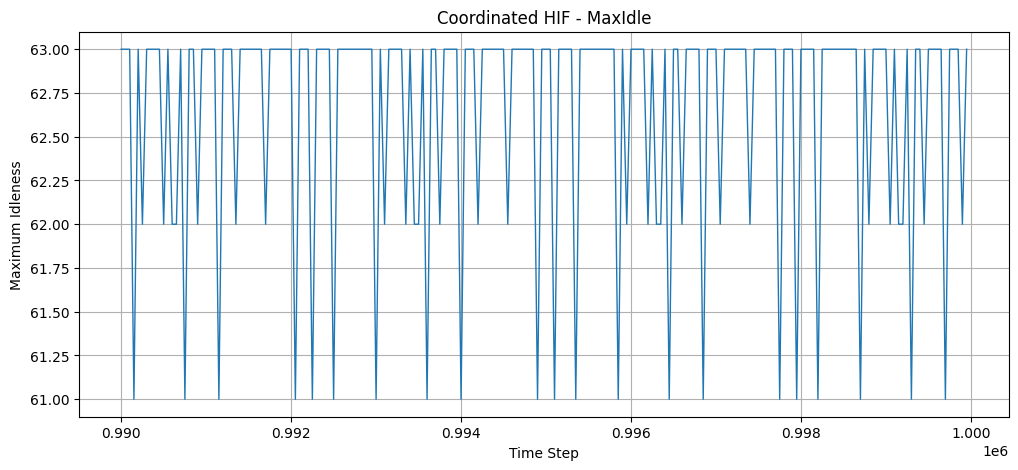

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 10% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng(seed)
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 10% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.10,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


### **2nd Case**

Removed 18 edges from 180 total edges


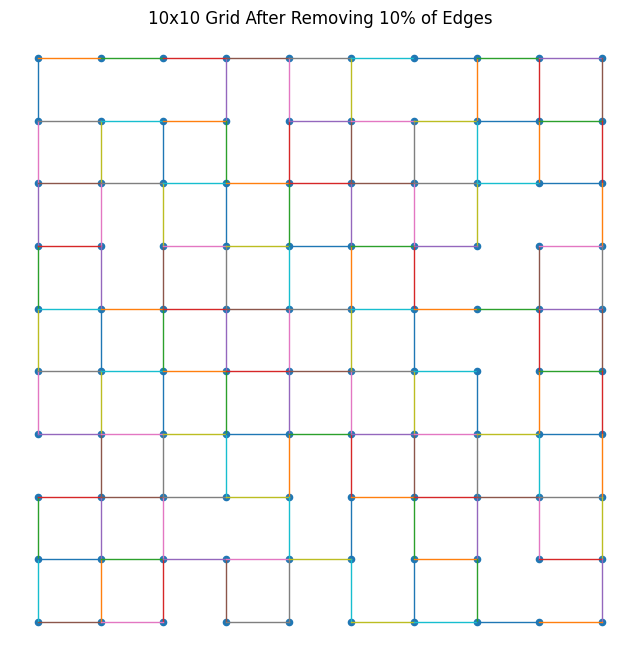

Uncoordinated: 100%|██████████| 1000000/1000000 [01:09<00:00, 14365.12it/s]



UNCOORDINATED
Mean IAI: 54.671417919989196
Mean MaxIdle: 119.329561
Maximum Observed Idleness: 375
Final IAI: 52.0
Final MaxIdle: 110.0


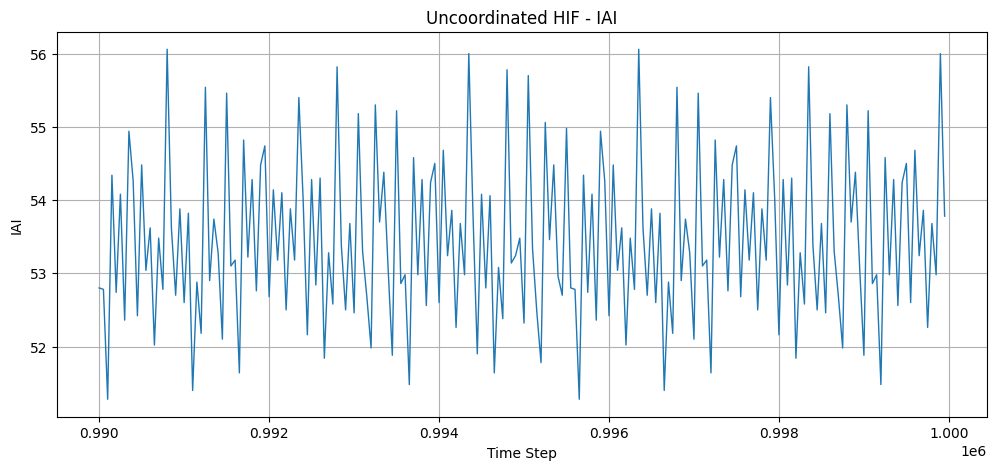

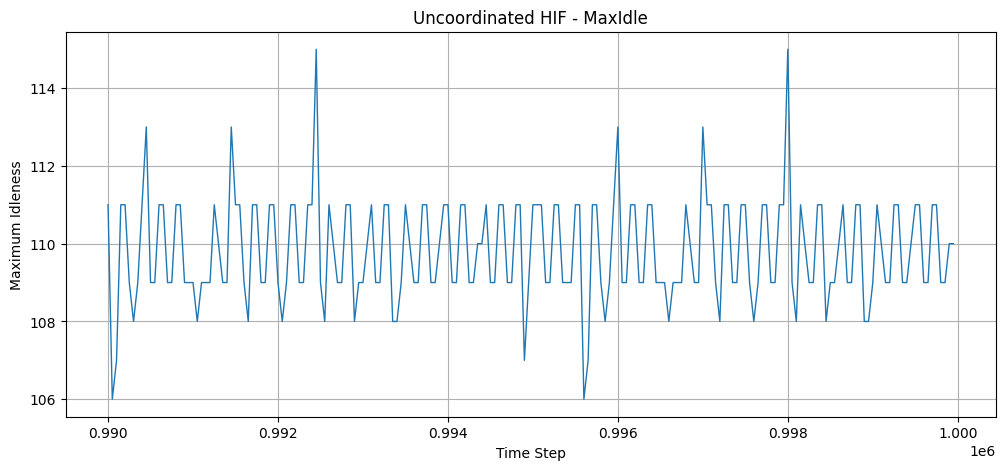

Coordinated: 100%|██████████| 1000000/1000000 [01:17<00:00, 12956.10it/s]



COORDINATED
Mean IAI: 31.244372759999653
Mean MaxIdle: 95.154324
Maximum Observed Idleness: 239
Final IAI: 26.26
Final MaxIdle: 62.0


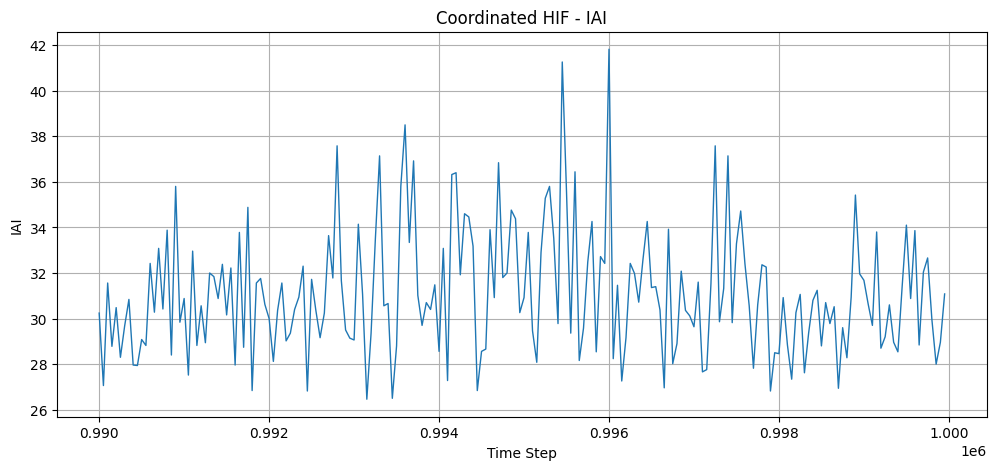

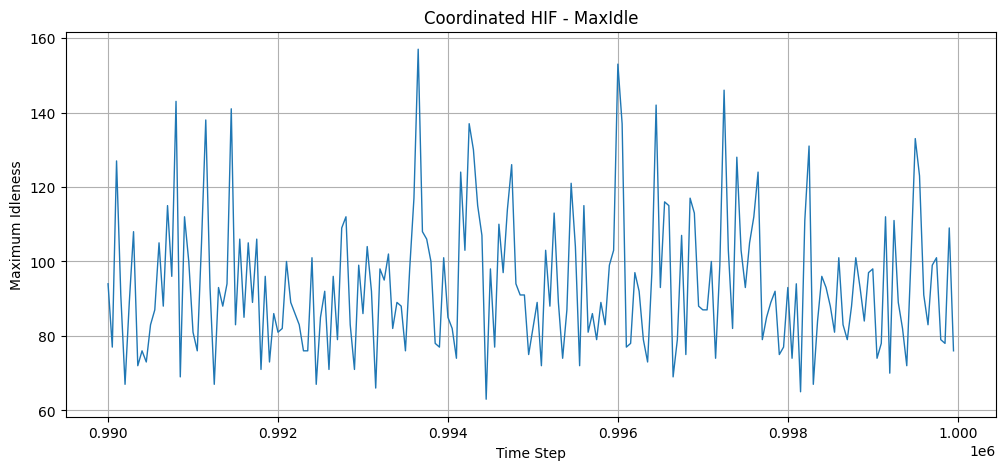

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 10% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 10% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.10,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


### **3rd Case**

Removed 18 edges from 180 total edges


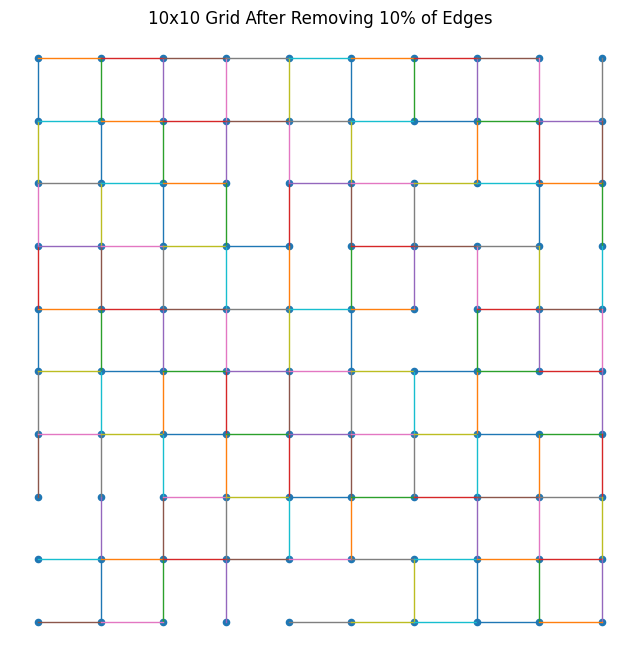

Uncoordinated: 100%|██████████| 1000000/1000000 [01:05<00:00, 15186.31it/s]



UNCOORDINATED
Mean IAI: 54.492954600010584
Mean MaxIdle: 112.18281
Maximum Observed Idleness: 511
Final IAI: 53.42
Final MaxIdle: 111.0


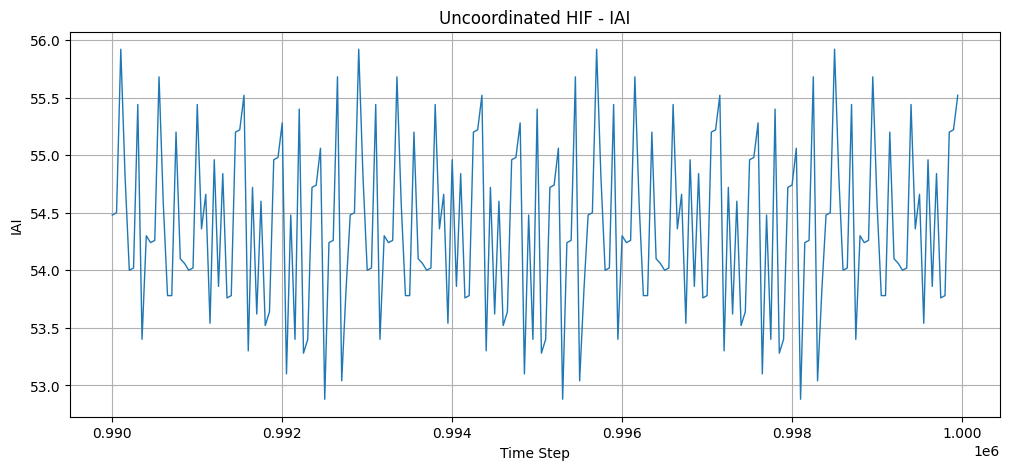

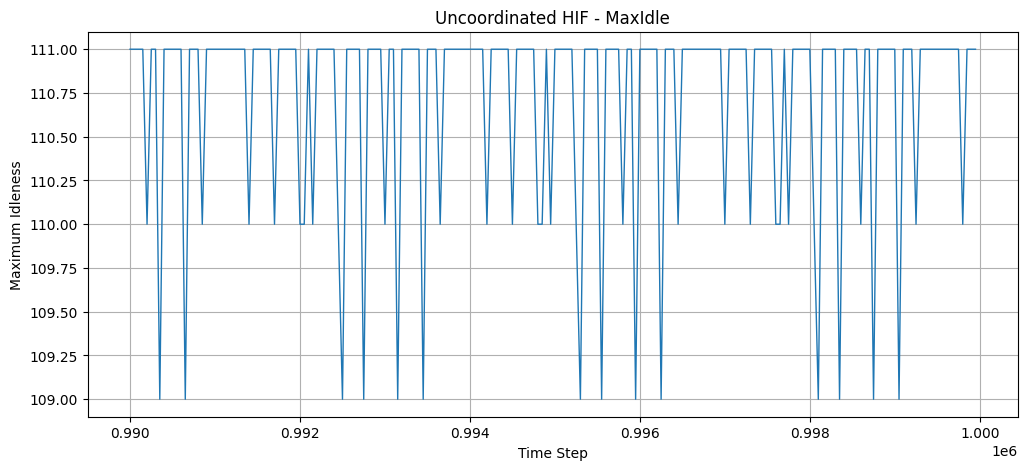

Coordinated: 100%|██████████| 1000000/1000000 [01:21<00:00, 12215.86it/s]



COORDINATED
Mean IAI: 28.11595863994015
Mean MaxIdle: 71.117754
Maximum Observed Idleness: 295
Final IAI: 27.08
Final MaxIdle: 59.0


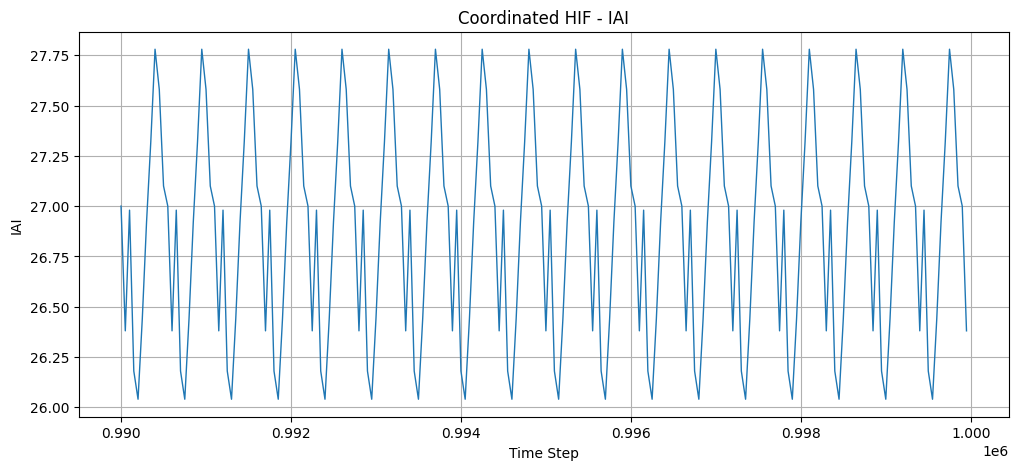

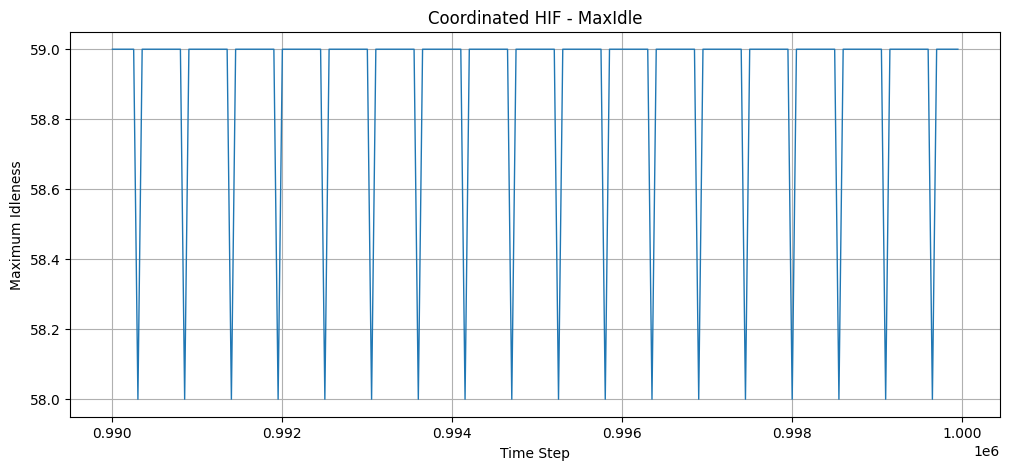

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 10% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 10% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.10,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


# **Uncoordinated and coordinated 2 Robots patrolling (20 percent removed)**

###**1st Case**

Removed 36 edges from 180 total edges


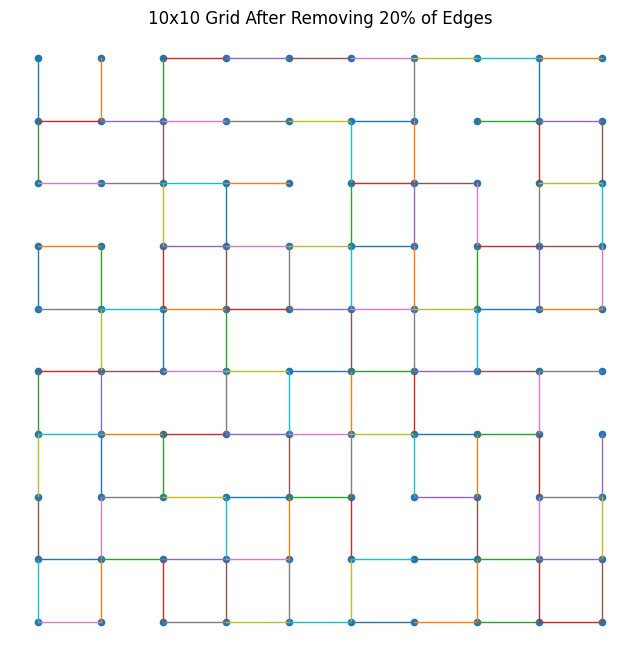

Uncoordinated: 100%|██████████| 1000000/1000000 [01:09<00:00, 14394.16it/s]



UNCOORDINATED
Mean IAI: 57.80388082000545
Mean MaxIdle: 126.340165
Maximum Observed Idleness: 477
Final IAI: 55.08
Final MaxIdle: 117.0


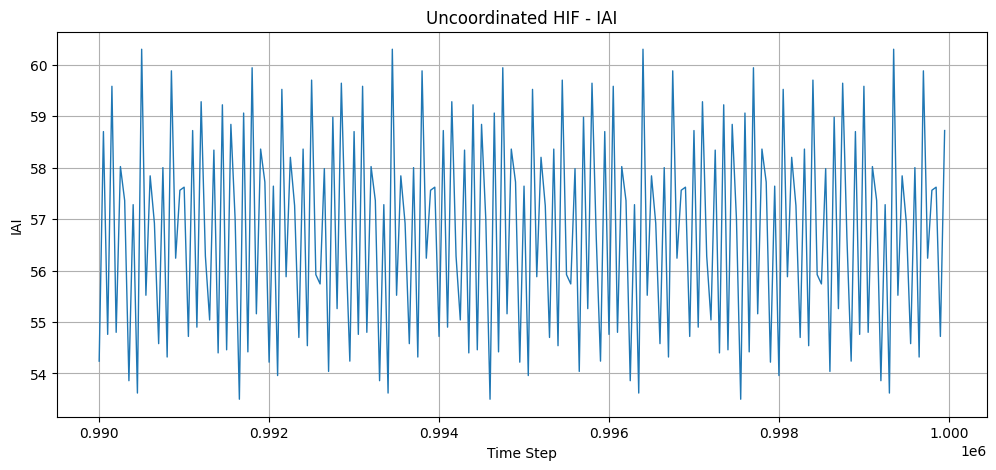

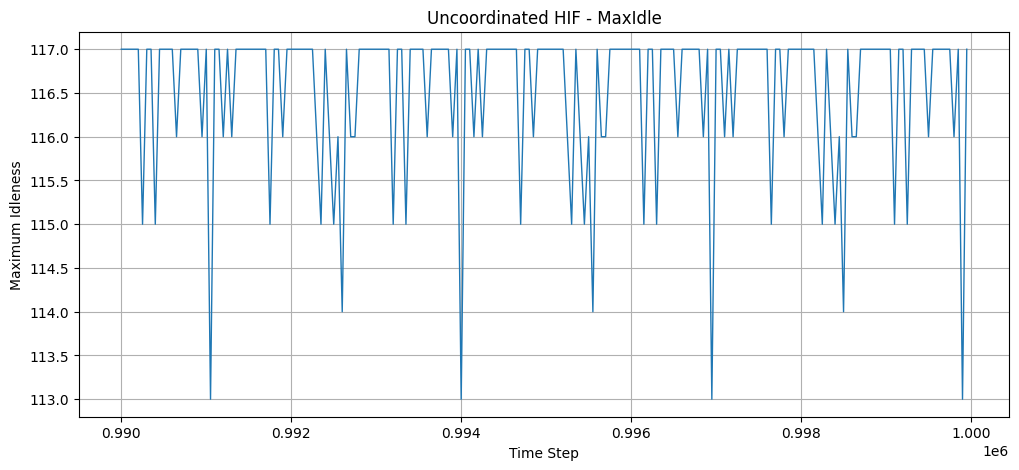

Coordinated: 100%|██████████| 1000000/1000000 [01:22<00:00, 12102.20it/s]



COORDINATED
Mean IAI: 33.507864979999354
Mean MaxIdle: 113.159478
Maximum Observed Idleness: 287
Final IAI: 30.78
Final MaxIdle: 78.0


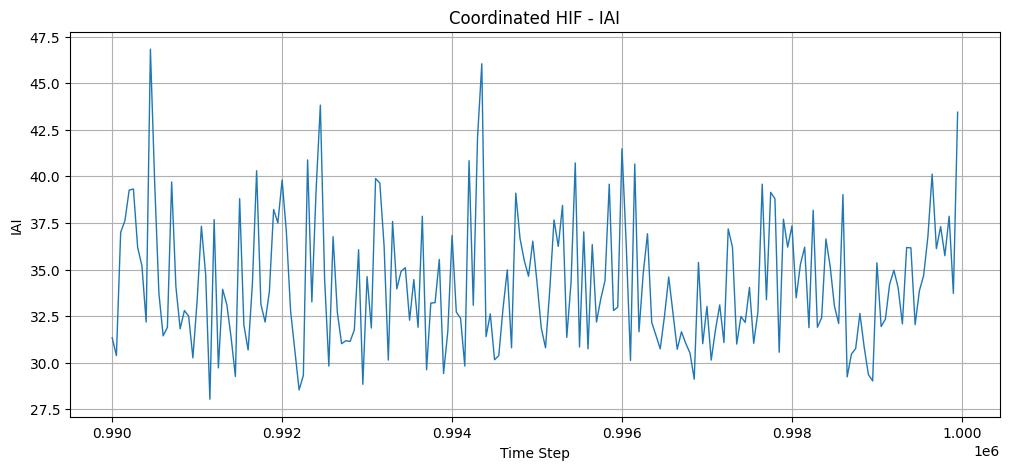

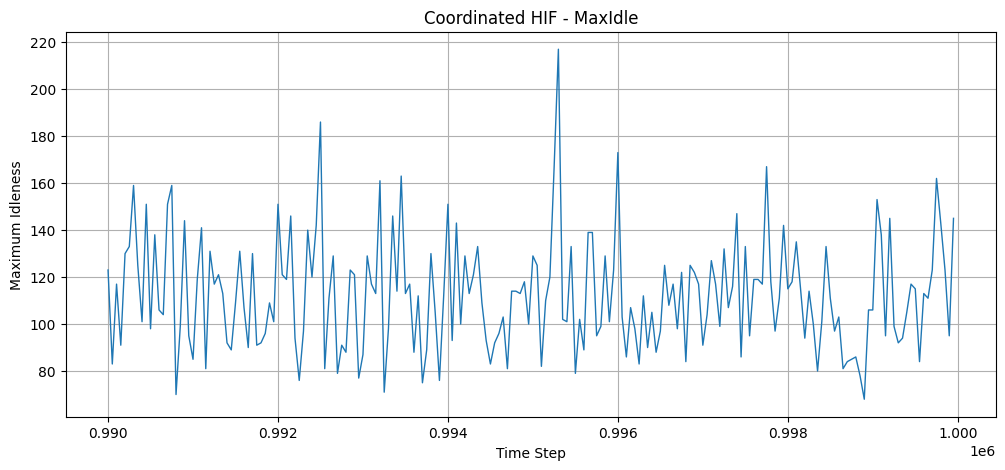

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 20% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 20% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.20,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


### **2nd Case**

Removed 36 edges from 180 total edges


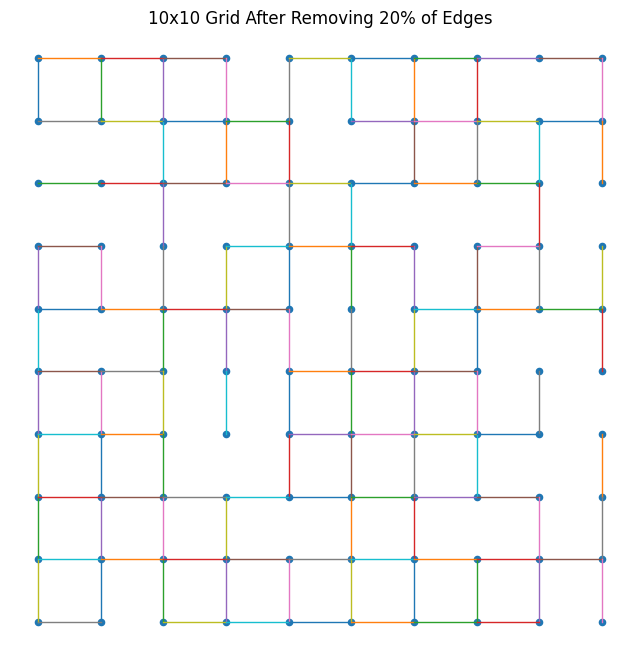

Uncoordinated: 100%|██████████| 1000000/1000000 [01:12<00:00, 13865.87it/s]



UNCOORDINATED
Mean IAI: 60.34935528001834
Mean MaxIdle: 129.339874
Maximum Observed Idleness: 487
Final IAI: 57.66
Final MaxIdle: 125.0


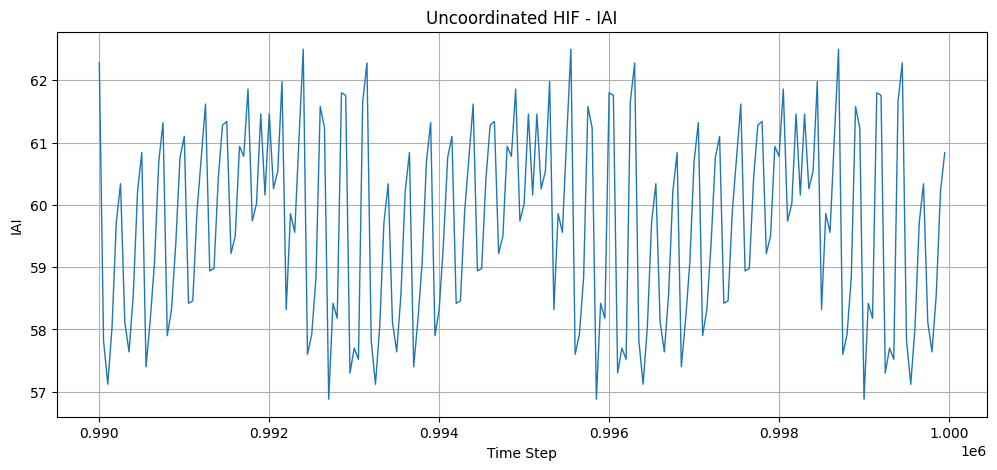

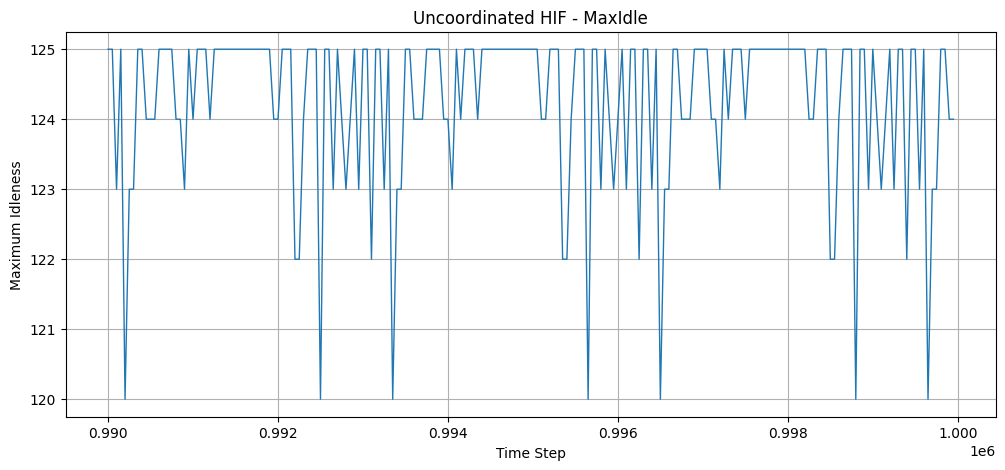

Coordinated: 100%|██████████| 1000000/1000000 [01:17<00:00, 12856.21it/s]



COORDINATED
Mean IAI: 35.17898464000096
Mean MaxIdle: 112.762234
Maximum Observed Idleness: 299
Final IAI: 32.86
Final MaxIdle: 140.0


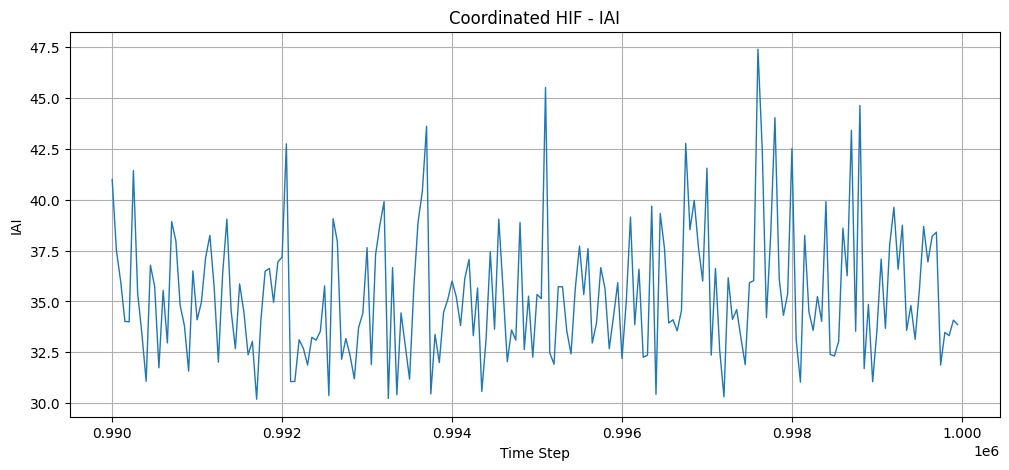

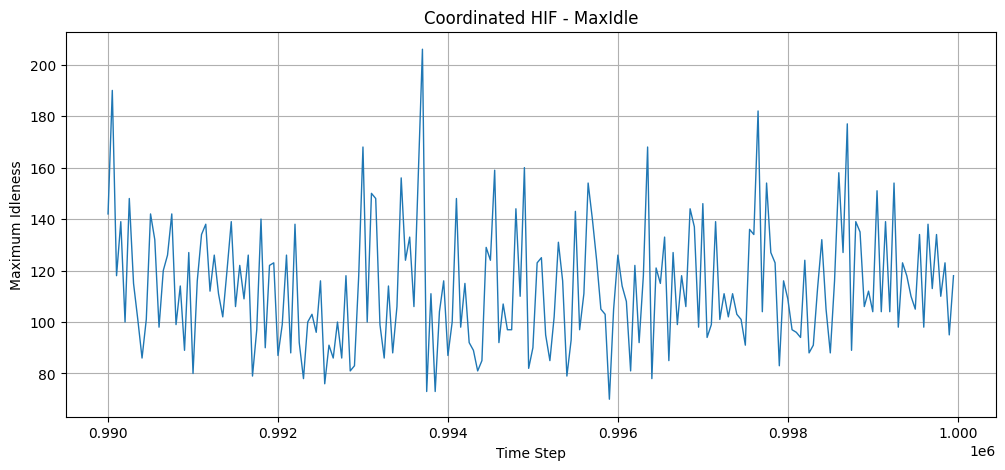

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 20% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 20% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.20,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


### **3rd Case**

Removed 36 edges from 180 total edges


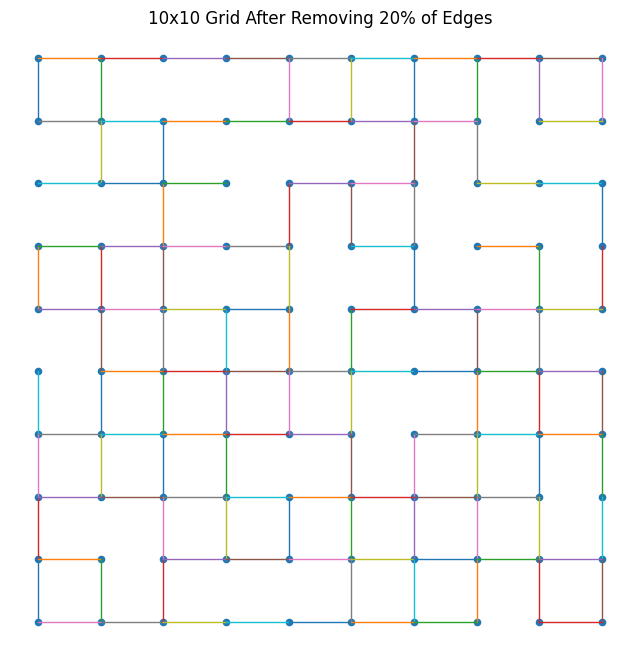

Uncoordinated: 100%|██████████| 1000000/1000000 [01:08<00:00, 14528.19it/s]



UNCOORDINATED
Mean IAI: 58.93483725996387
Mean MaxIdle: 124.110716
Maximum Observed Idleness: 405
Final IAI: 58.88
Final MaxIdle: 125.0


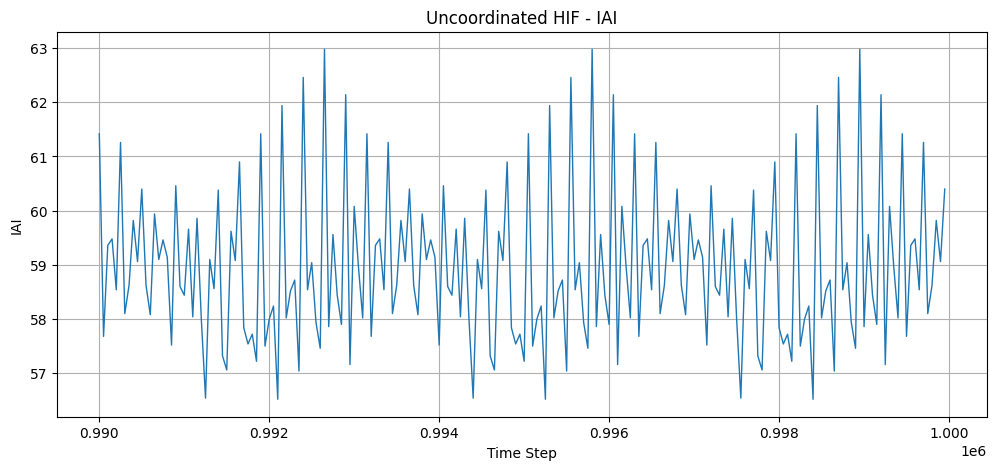

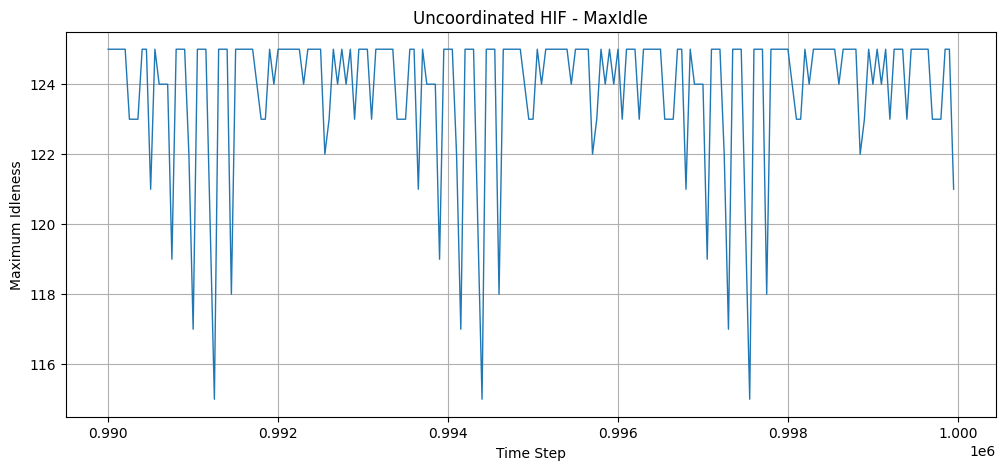

Coordinated: 100%|██████████| 1000000/1000000 [01:22<00:00, 12140.07it/s]



COORDINATED
Mean IAI: 27.497622879961064
Mean MaxIdle: 62.803614
Maximum Observed Idleness: 211
Final IAI: 27.16
Final MaxIdle: 63.0


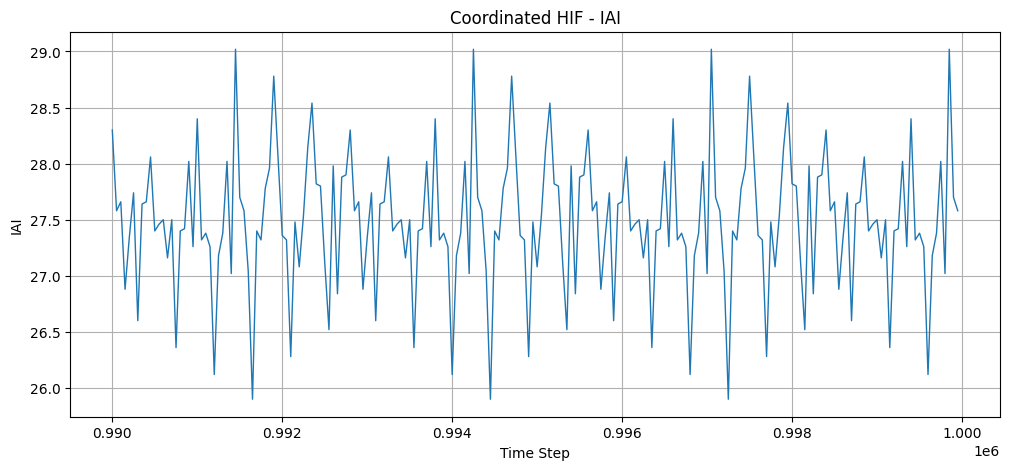

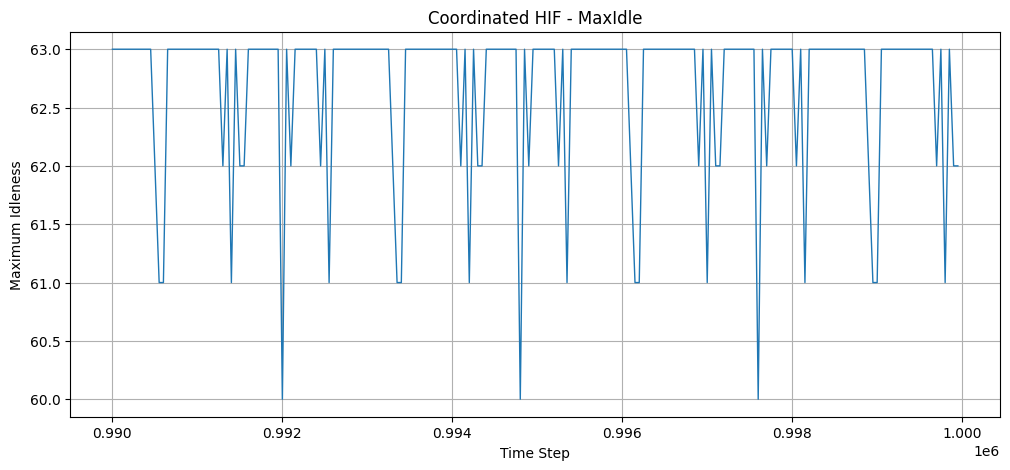

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 20% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 20% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.20,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


# **Uncoordinated and coordinated 2 Robots patrolling (30 percent removed)**

###**1st Case**

Removed 54 edges from 180 total edges


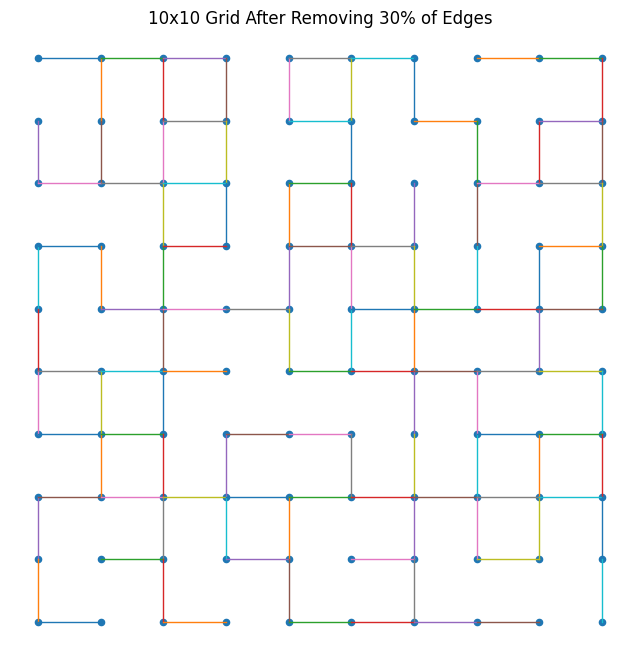

Uncoordinated: 100%|██████████| 1000000/1000000 [01:21<00:00, 12338.74it/s]



UNCOORDINATED
Mean IAI: 78.61260037999561
Mean MaxIdle: 193.121072
Maximum Observed Idleness: 361
Final IAI: 82.66
Final MaxIdle: 200.0


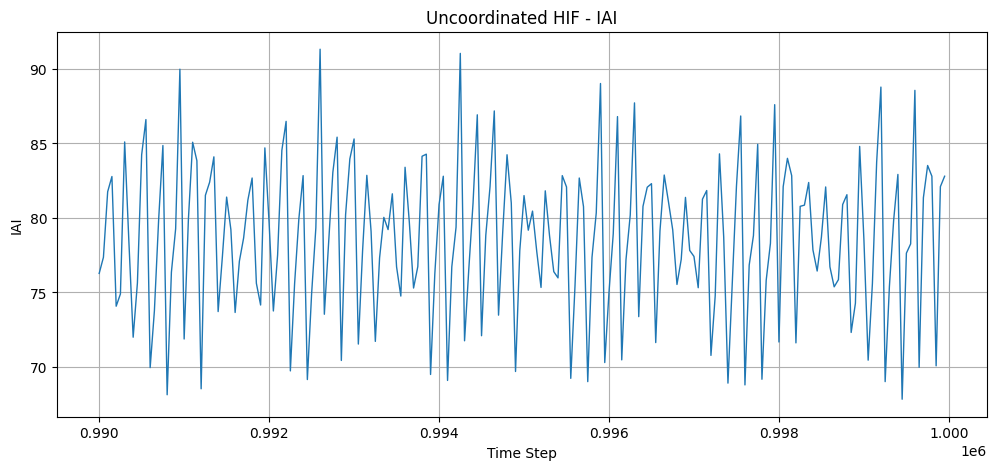

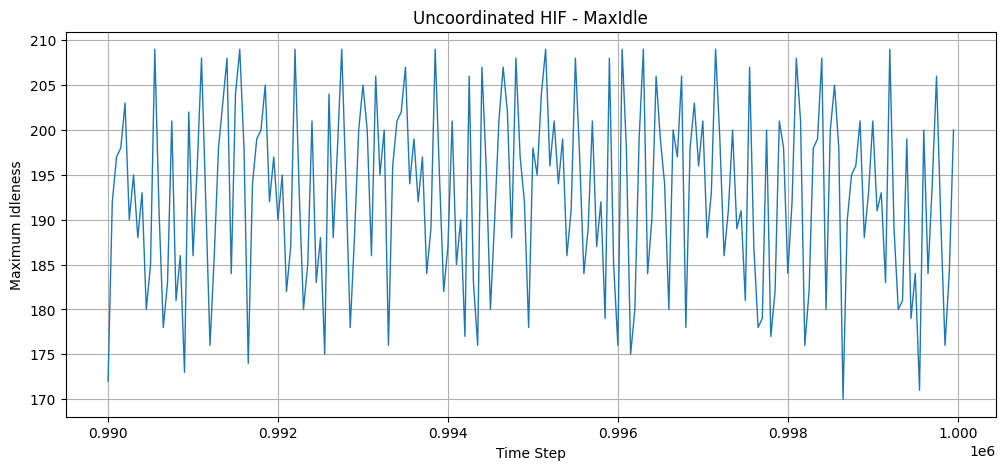

Coordinated: 100%|██████████| 1000000/1000000 [01:17<00:00, 12835.55it/s]



COORDINATED
Mean IAI: 37.905527679997896
Mean MaxIdle: 112.710585
Maximum Observed Idleness: 363
Final IAI: 33.7
Final MaxIdle: 103.0


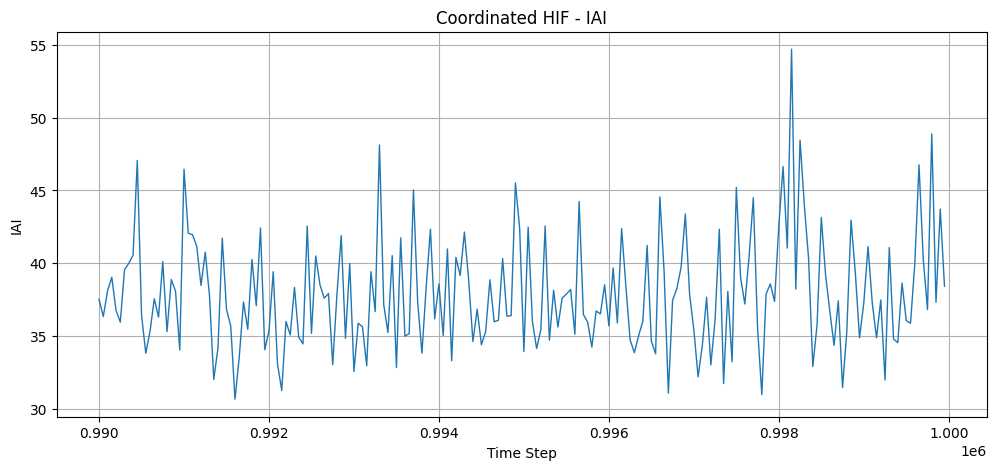

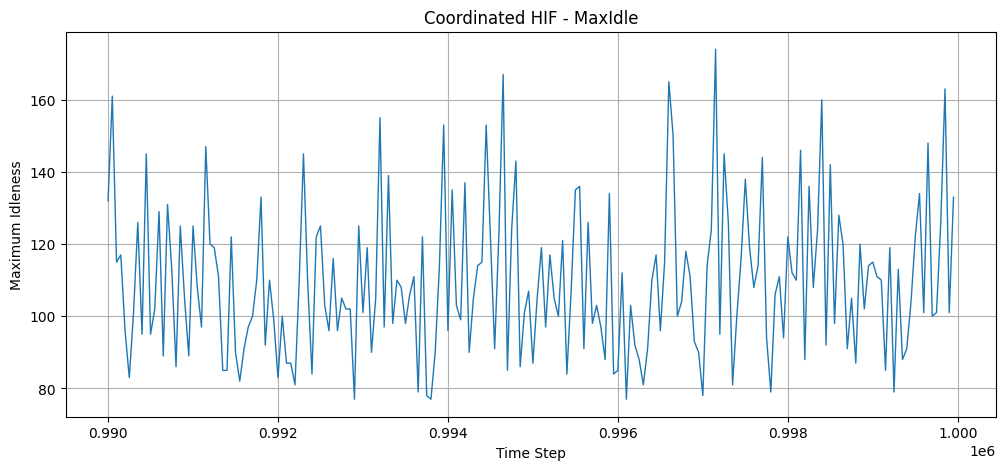

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 20% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 30% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.30,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


### **2nd Case**

Removed 36 edges from 180 total edges


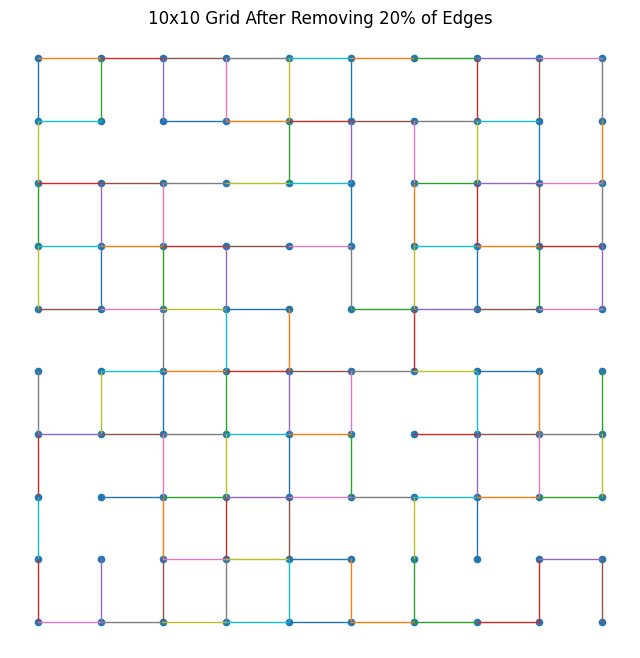

Uncoordinated: 100%|██████████| 1000000/1000000 [01:08<00:00, 14493.70it/s]



UNCOORDINATED
Mean IAI: 60.0024602599991
Mean MaxIdle: 124.408927
Maximum Observed Idleness: 423
Final IAI: 62.68
Final MaxIdle: 124.0


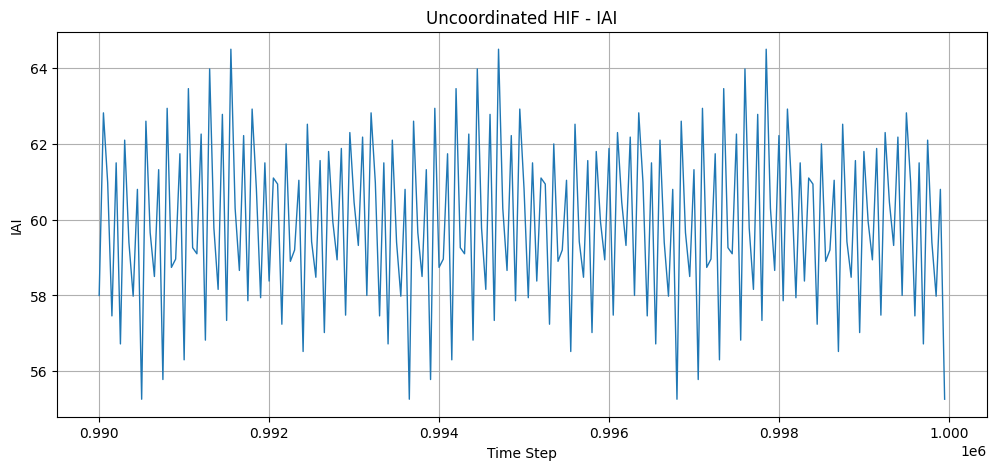

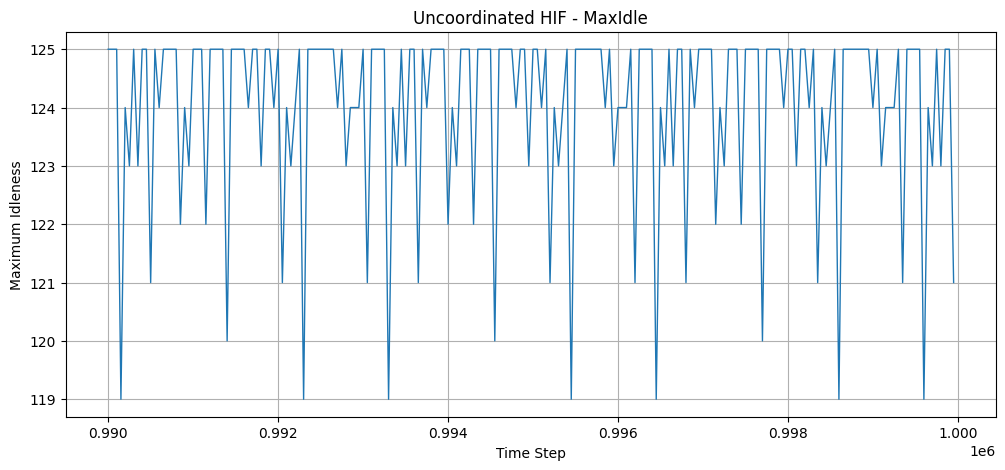

Coordinated: 100%|██████████| 1000000/1000000 [01:16<00:00, 13012.37it/s]



COORDINATED
Mean IAI: 32.696693179949776
Mean MaxIdle: 94.912891
Maximum Observed Idleness: 281
Final IAI: 30.96
Final MaxIdle: 103.0


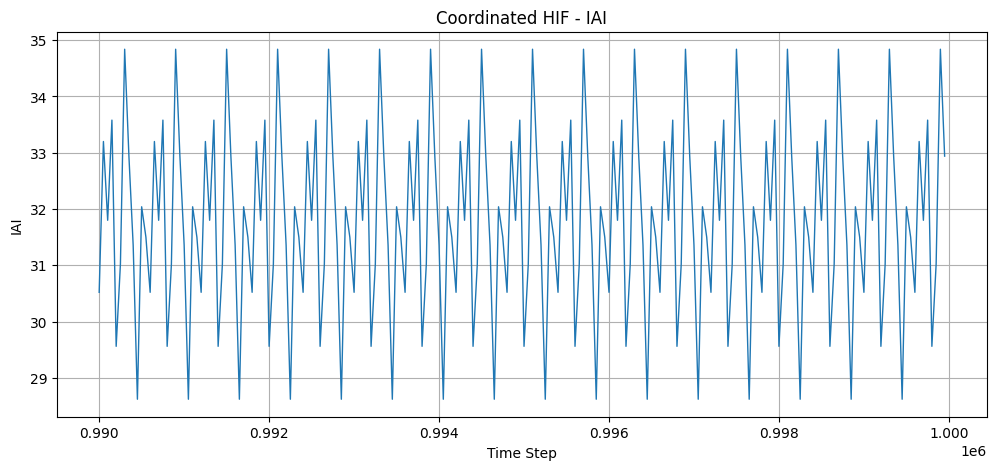

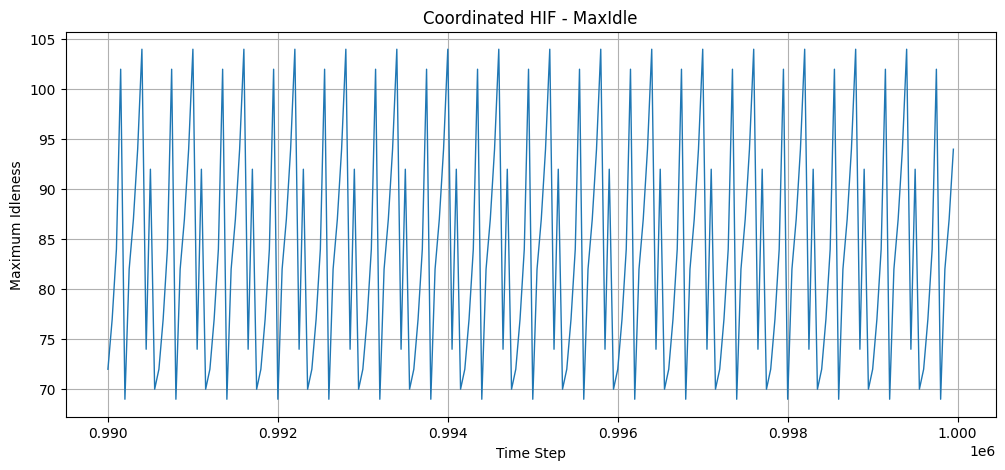

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 20% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 20% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.20,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()


### **3rd Case**

Removed 36 edges from 180 total edges


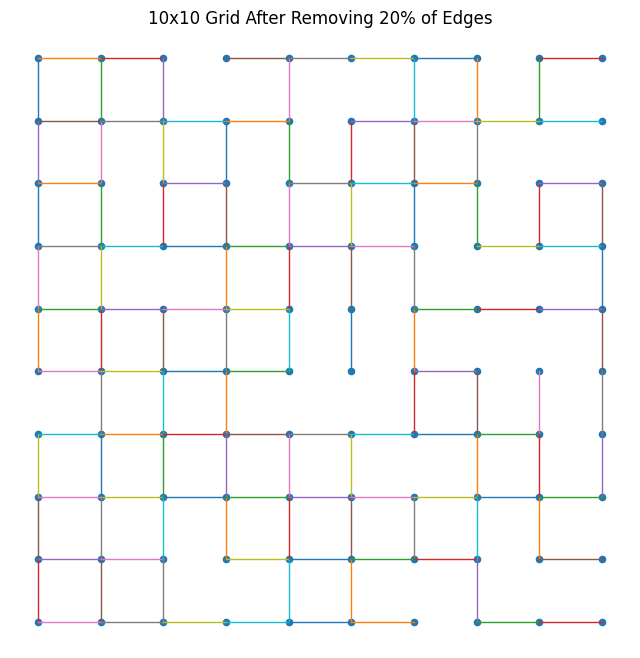

Uncoordinated: 100%|██████████| 1000000/1000000 [01:06<00:00, 15081.86it/s]



UNCOORDINATED
Mean IAI: 60.31097426003246
Mean MaxIdle: 127.181077
Maximum Observed Idleness: 377
Final IAI: 59.9
Final MaxIdle: 127.0


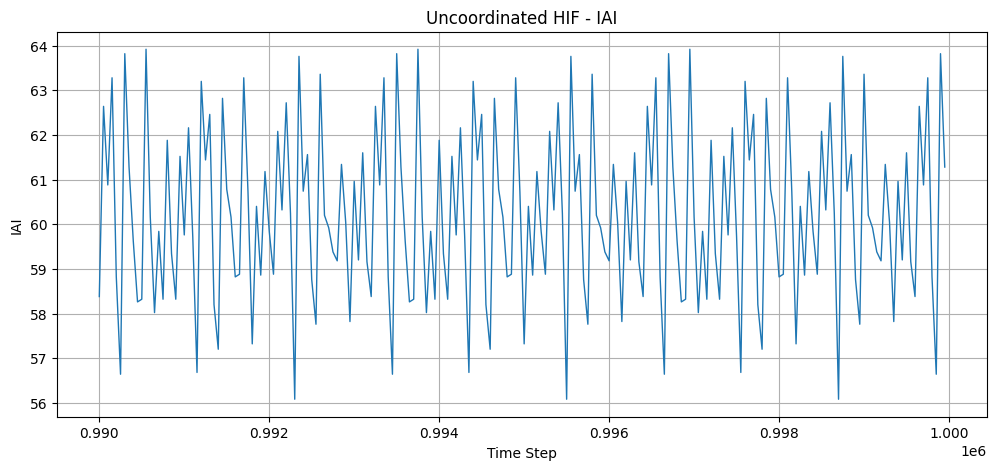

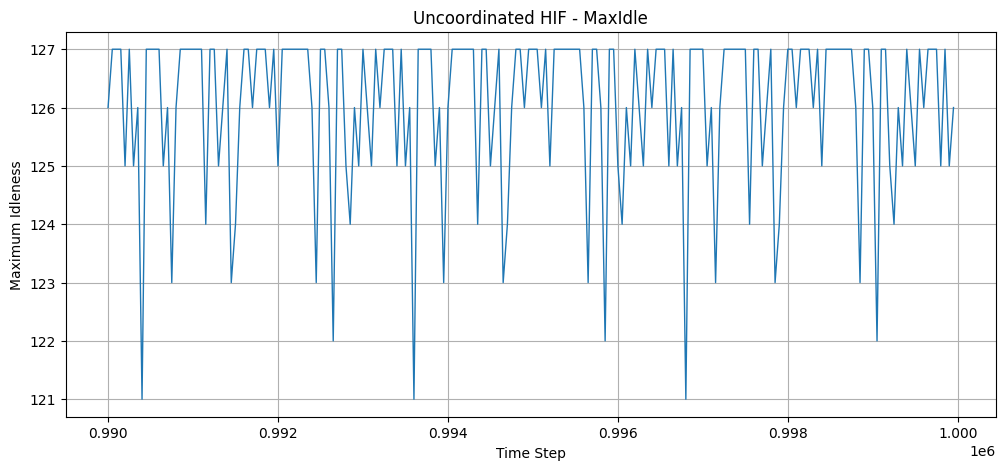

Coordinated: 100%|██████████| 1000000/1000000 [01:16<00:00, 13013.93it/s]



COORDINATED
Mean IAI: 29.1319828600561
Mean MaxIdle: 63.001697
Maximum Observed Idleness: 233
Final IAI: 29.98
Final MaxIdle: 60.0


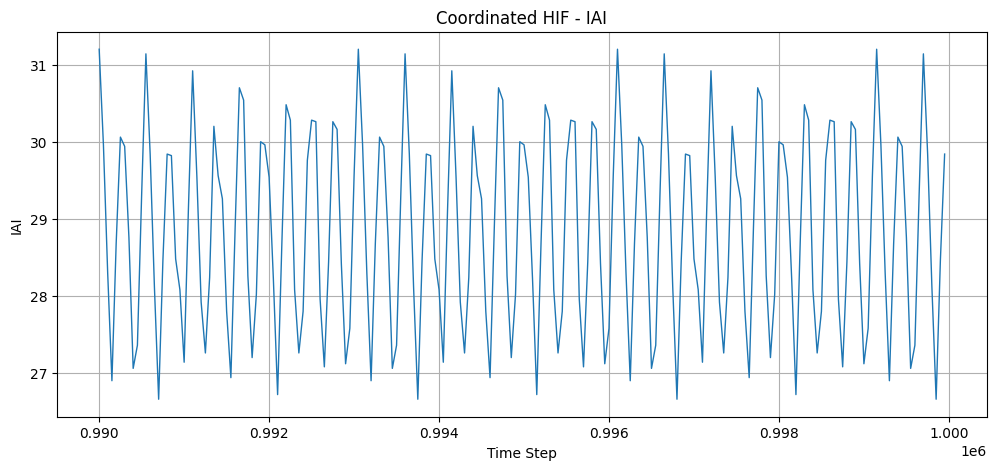

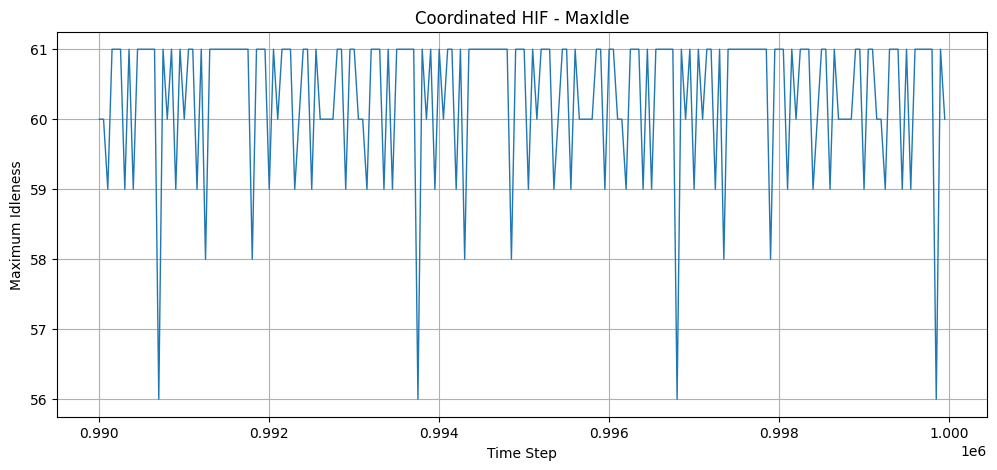

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ==========================================================
# Build Grid and Remove 20% Edges While Preserving Connectivity
# ==========================================================

def build_grid_graph(rows=10, cols=10, remove_fraction=0.10, seed=42):

    rng = np.random.default_rng()
    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:
                down = (r + 1) * cols + c
                neighbors[node].append(down)
                neighbors[down].append(node)
                edges.append((node, down))

            if c < cols - 1:
                right = r * cols + c + 1
                neighbors[node].append(right)
                neighbors[right].append(node)
                edges.append((node, right))

    def is_connected(adj):
        visited = np.zeros(N, dtype=bool)
        stack = [0]
        visited[0] = True

        while stack:
            u = stack.pop()

            for v in adj[u]:
                if not visited[v]:
                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(remove_fraction * len(edges))

    removed = 0
    candidate_edges = edges.copy()
    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):
            removed += 1
        else:
            neighbors[u].append(v)
            neighbors[v].append(u)

    print(f"Removed {removed} edges from {len(edges)} total edges")

    return [np.array(n, dtype=np.int32) for n in neighbors]


# ==========================================================
# Graph Visualization
# ==========================================================

def visualize_graph(neighbors, rows=10, cols=10):

    plt.figure(figsize=(8, 8))

    pos = {}

    for r in range(rows):
        for c in range(cols):
            node = r * cols + c
            pos[node] = (c, -r)

    for u in range(rows * cols):

        x1, y1 = pos[u]

        for v in neighbors[u]:

            if v > u:

                x2, y2 = pos[v]

                plt.plot(
                    [x1, x2],
                    [y1, y2],
                    linewidth=1
                )

    xs = []
    ys = []

    for node in range(rows * cols):
        x, y = pos[node]
        xs.append(x)
        ys.append(y)

    plt.scatter(xs, ys, s=20)

    plt.title("10x10 Grid After Removing 20% of Edges")
    plt.axis("equal")
    plt.axis("off")
    plt.show()


# ==========================================================
# Robot
# ==========================================================

class HIFRobot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def move(self, idleness):

        nbrs = self.neighbors[self.position]

        nbr_idle = idleness[nbrs]

        max_idle = nbr_idle.max()

        candidates = nbrs[nbr_idle == max_idle]

        next_node = self.rng.choice(candidates)

        self.position = next_node

        return next_node


# ==========================================================
# Simulation
# ==========================================================

class PatrollingSimulation:

    def __init__(
        self,
        neighbors,
        coordinated=False,
        num_steps=1_000_000,
        seed=42
    ):

        self.neighbors = neighbors
        self.coordinated = coordinated
        self.num_steps = num_steps
        self.N = len(neighbors)

        self.rng = np.random.default_rng(seed)

        self.robot1 = HIFRobot(
            0,
            neighbors,
            self.rng
        )

        self.robot2 = HIFRobot(
            self.N - 1,
            neighbors,
            self.rng
        )

        self.idleness = np.zeros(
            self.N,
            dtype=np.int32
        )

        self.tail_start = int(0.9 * num_steps)
        self.tail_length = num_steps - self.tail_start

        self.iai_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.max_tail = np.zeros(
            self.tail_length,
            dtype=np.float32
        )

        self.iai_sum = 0.0
        self.max_sum = 0.0
        self.global_max_idle = 0

    def step(self):

        self.idleness += 1

        node1 = self.robot1.move(self.idleness)

        if not self.coordinated:

            node2 = self.robot2.move(self.idleness)

        else:

            nbrs = self.neighbors[
                self.robot2.position
            ]

            filtered = [
                n for n in nbrs
                if n != node1
            ]

            if len(filtered) > 0:

                filtered = np.array(
                    filtered,
                    dtype=np.int32
                )

                idle_vals = self.idleness[filtered]

                mx = idle_vals.max()

                candidates = filtered[
                    idle_vals == mx
                ]

                node2 = self.rng.choice(candidates)

                self.robot2.position = node2

            else:

                node2 = self.robot2.move(
                    self.idleness
                )

        self.idleness[node1] = 0
        self.idleness[node2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

    def run(self):

        tail_idx = 0

        for t in tqdm(
            range(self.num_steps),
            desc="Coordinated" if self.coordinated else "Uncoordinated"
        ):

            iai, max_idle = self.step()

            self.iai_sum += iai
            self.max_sum += max_idle

            self.global_max_idle = max(
                self.global_max_idle,
                int(max_idle)
            )

            if t >= self.tail_start:

                self.iai_tail[tail_idx] = iai
                self.max_tail[tail_idx] = max_idle

                tail_idx += 1

    def print_statistics(self):

        name = (
            "COORDINATED"
            if self.coordinated
            else "UNCOORDINATED"
        )

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        print("Mean IAI:", self.iai_sum / self.num_steps)
        print("Mean MaxIdle:", self.max_sum / self.num_steps)
        print("Maximum Observed Idleness:", self.global_max_idle)
        print("Final IAI:", self.iai_tail[-1])
        print("Final MaxIdle:", self.max_tail[-1])

    def plot_metrics(self):

        window = 10000

        x = np.arange(
            self.num_steps - window,
            self.num_steps
        )

        iai = self.iai_tail[-window:]
        mx = self.max_tail[-window:]

        # Downsample only for plotting speed/readability
        stride = 50

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            iai[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - IAI"
        )
        plt.xlabel("Time Step")
        plt.ylabel("IAI")
        plt.grid(True)

        plt.figure(figsize=(12, 5))
        plt.plot(
            x[::stride],
            mx[::stride],
            linewidth=1
        )
        plt.title(
            ("Coordinated" if self.coordinated else "Uncoordinated")
            + " HIF - MaxIdle"
        )
        plt.xlabel("Time Step")
        plt.ylabel("Maximum Idleness")
        plt.grid(True)

        plt.show()


# ==========================================================
# MAIN
# ==========================================================

if __name__ == "__main__":

    STEPS = 1_000_000
    SEED = 42

    neighbors = build_grid_graph(
        rows=10,
        cols=10,
        remove_fraction=0.20,
        seed=SEED
    )

    visualize_graph(
        neighbors,
        rows=10,
        cols=10
    )

    uncoord = PatrollingSimulation(
        neighbors,
        coordinated=False,
        num_steps=STEPS,
        seed=SEED
    )

    uncoord.run()
    uncoord.print_statistics()
    uncoord.plot_metrics()

    coord = PatrollingSimulation(
        neighbors,
        coordinated=True,
        num_steps=STEPS,
        seed=SEED
    )

    coord.run()
    coord.print_statistics()
    coord.plot_metrics()
